# Who gets the carbon dividend?

Name: **VIKTORIJA LODIENĖ**

**Recommendation for the finance minister**

### Use an income-based sliding scale for the carbon dividend

Return the EUR 137,916 in carbon revenue through a sliding scale that gives larger dividends to lower-income households and tapers dividends to zero at median income. In the table, the two lowest income quintiles gain an average EUR 1,473 and EUR 324 per household under this rule; the upper three quintiles have average net costs of EUR 358, EUR 703, and EUR 736. The figure shows that households with similar incomes can still have different outcomes because their emissions charges differ. At the 80% median challenge cutoff, 71 households receive a positive dividend, so the recommendation still fits a priority of targeting lower incomes, though it reaches fewer households. This is a one-year calculation that holds incomes and emissions fixed and does not adjust for household size.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

h = pd.read_csv(Path("households.csv"))
h["tax"] = 100 * (h["heat_t"] + h["travel_t"])
revenue = h["tax"].sum()
h["equal_dividend"] = revenue / len(h)
h["net_equal"] = h["tax"] - h["equal_dividend"]
print(f"{len(h)} households | Revenue EUR {revenue:,.2f} | Equal dividend EUR {revenue / len(h):,.2f}")
print("Equal-rule unallocated revenue (EUR):", round(revenue - h["equal_dividend"].sum(), 6))
assert abs(revenue - h["equal_dividend"].sum()) < 0.01

print(h.head(5).to_string())

240 households | Revenue EUR 137,916.00 | Equal dividend EUR 574.65
Equal-rule unallocated revenue (EUR): 0.0
     id  people   area  income_eur  heat_t  travel_t    tax  equal_dividend  net_equal
0  H001       3  Urban       36174    1.96      0.94  290.0          574.65    -284.65
1  H002       3  Rural       40770    1.92      3.43  535.0          574.65     -39.65
2  H003       4  Urban       69624    4.57      1.80  637.0          574.65      62.35
3  H004       2  Rural       75001    3.11      1.41  452.0          574.65    -122.65
4  H005       1  Urban       38465    1.99      1.01  300.0          574.65    -274.65


## Priority: a median-income sliding scale
Direct more support to lower-income households while tapering support gradually. Set a support cutoff at median annual household disposable income. Below that cutoff, a household's dividend weight declines linearly as income rises: weight = 1 - income / cutoff. Households at or above the cutoff receive no dividend. Allocate all carbon-tax revenue in proportion to these weights. This uses pre-policy income, not emissions or the tax bill. The dataset records total household income rather than equivalised income, so the rule does not adjust for household size.


In [2]:
# Optional helper for rules expressed as nonnegative household weights.
# Example: passing a Series of ones reproduces the equal household dividend.
def distribute(weights):
    weights = pd.Series(weights, index=h.index, dtype=float)
    assert np.isfinite(weights).all() and (weights >= 0).all() and weights.sum() > 0
    return revenue * weights / weights.sum()

# A sliding scale that tapers dividend weights to zero at median income.
support_cutoff = h["income_eur"].median()
h["dividend_weight"] = (1 - h["income_eur"] / support_cutoff).clip(lower=0)
h["eligible"] = h["dividend_weight"] > 0
print(f"Support cutoff: EUR {support_cutoff:,.2f} | Households with positive weight: {h['eligible'].sum()}")

# All revenue is allocated in proportion to each household's income-based weight.
h["proposal"] = distribute(h["dividend_weight"])
h["net_proposal"] = h["tax"] - h["proposal"]
print(h.head(5).to_string())

Support cutoff: EUR 38,662.50 | Households with positive weight: 120
     id  people   area  income_eur  heat_t  travel_t    tax  equal_dividend  net_equal  dividend_weight  eligible    proposal  net_proposal
0  H001       3  Urban       36174    1.96      0.94  290.0          574.65    -284.65         0.064365      True  276.504455     13.495545
1  H002       3  Rural       40770    1.92      3.43  535.0          574.65     -39.65         0.000000     False    0.000000    535.000000
2  H003       4  Urban       69624    4.57      1.80  637.0          574.65      62.35         0.000000     False    0.000000    637.000000
3  H004       2  Rural       75001    3.11      1.41  452.0          574.65    -122.65         0.000000     False    0.000000    452.000000
4  H005       1  Urban       38465    1.99      1.01  300.0          574.65    -274.65         0.005108      True   21.944798    278.055202


In [3]:
print("Unallocated revenue (EUR):", revenue - h["proposal"].sum())
assert h["proposal"].notna().all() and (h["proposal"] >= 0).all()
assert h["dividend_weight"].sum() > 0
assert abs(h["proposal"].sum() - revenue) < 0.01

Unallocated revenue (EUR): -2.9103830456733704e-11


### Table
*Give the table a title. Include units, group sizes and outcomes under both rules. Build it from the CSV in code.*

In [4]:
# Table: average annual net cost by pre-policy income quintile.
h["net_equal_pct_income"] = 100 * h["net_equal"] / h["income_eur"]
h["net_proposal_pct_income"] = 100 * h["net_proposal"] / h["income_eur"]
h["income_quintile"] = pd.qcut(
    h["income_eur"].rank(method="first"),
    q=5,
    labels=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"]
)

table = (
    h.groupby("income_quintile", observed=True)
    .agg(
        households=("id", "count"),
        mean_income_eur=("income_eur", "mean"),
        equal_rule_mean_net_cost_eur=("net_equal", "mean"),
        equal_rule_mean_net_cost_pct_income=("net_equal_pct_income", "mean"),
        proposal_mean_net_cost_eur=("net_proposal", "mean"),
        proposal_mean_net_cost_pct_income=("net_proposal_pct_income", "mean"),
    )
    .rename(columns={
        "households": "Number of households",
        "mean_income_eur": "Average annual income (EUR)",
        "equal_rule_mean_net_cost_eur": "Equal dividend: average net cost (EUR)",
        "equal_rule_mean_net_cost_pct_income": "Equal dividend: average net cost (% of income)",
        "proposal_mean_net_cost_eur": "Sliding scale: average net cost (EUR)",
        "proposal_mean_net_cost_pct_income": "Sliding scale: average net cost (% of income)",
    })
)

print("Table. Average annual household net cost by pre-policy income quintile")
print("EUR per household per year; net cost as a percent of annual household income.")
display(table.round(2))

Table. Average annual household net cost by pre-policy income quintile
EUR per household per year; net cost as a percent of annual household income.


,Number of households,Average annual income (EUR),Equal dividend: average net cost (EUR),Equal dividend: average net cost (% of income),Sliding scale: average net cost (EUR),Sliding scale: average net cost (% of income)
income_quintile,,,,,,
Q1 lowest,48,21443.33,-134.46,-0.66,-1473.08,-7.54
Q2,48,31045.75,-52.05,-0.17,-323.72,-1.08
Q3,48,39000.42,-102.98,-0.27,358.01,0.89
Q4,48,51357.65,127.87,0.25,702.52,1.38
Q5 highest,48,81064.33,161.62,0.20,736.27,0.94


### Figure
*Give the figure a headline, labelled axes and units. Show something economically important beyond the table.*

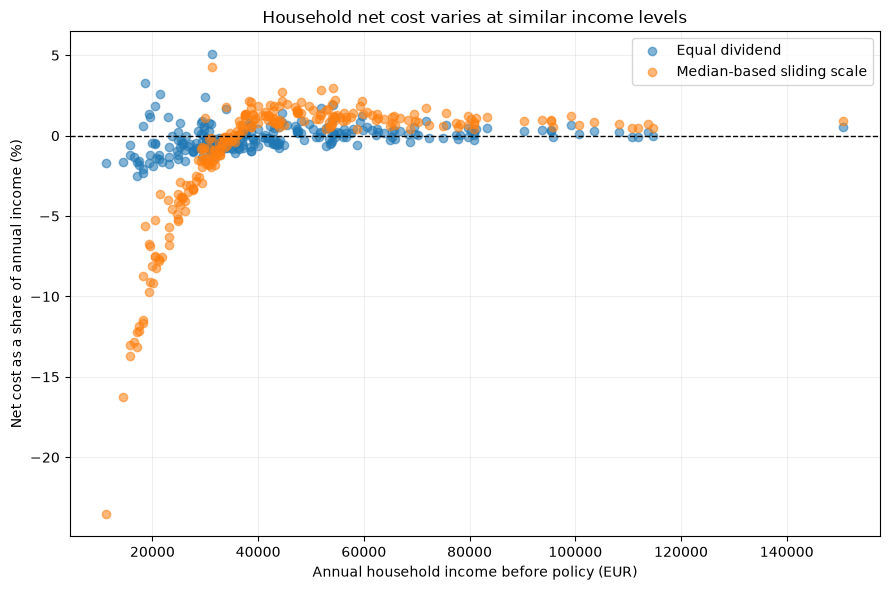

In [5]:
plt.figure(figsize=(9, 6))

plt.scatter(
    h["income_eur"],
    h["net_equal_pct_income"],
    alpha=0.55,
    label="Equal dividend",
)

plt.scatter(
    h["income_eur"],
    h["net_proposal_pct_income"],
    alpha=0.55,
    label="Median-based sliding scale",
)

plt.axhline(0, color="black", linewidth=1, linestyle="--")

plt.title("Household net cost varies at similar income levels")
plt.xlabel("Annual household income before policy (EUR)")
plt.ylabel("Net cost as a share of annual income (%)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Each dot is one household. Above zero means the household pays more in tax than it receives in dividends; below zero means it receives more than it pays. The figure can reveal differences between households with similar incomes that the quintile averages conceal.

### Challenge and AI check
*Show one recalculation that could have changed your recommendation. State the result. In one sentence, identify an AI suggestion you checked and what you did with it.*

In [6]:
# Challenge: what if support tapered to zero at 80% of median income?
challenge_cutoff = 0.80 * h["income_eur"].median()

challenge_weights = (1 - h["income_eur"] / challenge_cutoff).clip(lower=0)
challenge_dividend = revenue * challenge_weights / challenge_weights.sum()
challenge_net_cost = h["tax"] - challenge_dividend

print(f"Challenge cutoff: EUR {challenge_cutoff:,.2f}")
print(f"Households with positive dividend: {(challenge_weights > 0).sum()}")
print(f"Mean net cost under challenge rule: EUR {challenge_net_cost.mean():,.2f}")
print(f"Mean net cost as % of income: "
      f"{(100 * challenge_net_cost / h['income_eur']).mean():.2f}%")
print(f"Revenue not allocated: EUR {revenue - challenge_dividend.sum():.6f}")

Challenge cutoff: EUR 30,930.00
Households with positive dividend: 71
Mean net cost under challenge rule: EUR -0.00
Mean net cost as % of income: -1.47%
Revenue not allocated: EUR 0.000000


**Challenge note:** At a cutoff of 80% of median income (EUR 30,930), 71 households receive positive dividends. The full revenue is allocated, and the mean net cost is approximately EUR 0 per household, as expected when all revenue is returned. The mean net cost is −1.47% of income, indicating an average net gain relative to income under this measure. This recalculation alone does not overturn my recommendation: it shows that a lower cutoff concentrates support among fewer households, consistent with prioritizing lower incomes.

**AI check:** AI suggested comparing net costs as a percentage of household income. I checked that the calculation divides each household’s net cost by its annual income and multiplies by 100, so I kept the measure.